# **Dynamic Obstacle Avoidance** 🏎️🏎️

---

In our previous static obstacle avoidance notebook, we forced the policy to react
to the *lidar*, not memorized coordinates, by randomizing where a stationary
obstacle sat every episode. Here we go one step further: the obstacle **moves** which is the case in our head-to-head racing scenerio where we need to avoid these dynamic obstacles.

A real opponent car, controlled by a randomized pure-pursuit controller,
shares the track with the ego car. Every episode randomizes:
- The opponent's **cruise speed**
- The opponent's **spawn offset** along the track (ahead of or behind ego)
- The opponent's **lookahead distance** (how tightly it hugs the racing line)

Without this randomization, the ego could solve "avoid the other car" by
memorizing one fixed speed and position. With it, the only way to survive is to react to what the lidar
sees, in real time, regardless of where the opponent happens to be or how
fast it's going this episode.

Same PPO algorithm as every notebook in this series — network, GAE, clipped
loss, unchanged. Only the environment (now genuinely multi-agent) and the
opponent's behavior are new.



<p align="left">
  <img src="https://raw.githubusercontent.com/dhyeyshah28/RL_for_Roboracer/main/assets/images/dynamic_obs.gif" width="530"/>
</p>


---


## 📋 Why This Uses Real Multi-Agent Support, Not a Workaround

Static obstacle avoidance had to paint obstacles directly into the map image
because we didn't have a reliable way to place a *moving* object into the
gym's collision/lidar pipeline otherwise. Dynamic obstacles don't have that
problem — the gym's `num_agents` parameter is the **actual, intended**
mechanism for this: a second agent is a full car, with its own physics, own
lidar returns, and proper collision detection against the ego.

| | Static Obstacle Avoidance | Dynamic Obstacle Avoidance |
|---|---|---|
| Obstacle mechanism | Painted into the map's occupancy grid | Real second agent (`num_agents=2`) |
| What varies each episode | Position, size, count of painted obstacles | Opponent speed, spawn offset, lookahead |
| Obstacle behavior | Fixed once placed | Moves — controlled by pure pursuit |
| Risk level | Needed multiple rounds of file-path debugging | Documented, intended gym feature |

---


---

# **Section 1 — Setup** 🔧

In [ ]:
# ── Install all dependencies ──────────────────────────────────────────────────
# f1tenth_gym: the race car simulator (dev-humble branch = latest stable)
!pip install -q git+https://github.com/f1tenth/f1tenth_gym.git@dev-humble

# stable-baselines3: we use only its VecEnv utilities (parallel envs, reward
# normalization) for running rollouts — the PPO algorithm itself is ours
!pip install -q stable-baselines3[extra]

# wandb: experiment tracking — we will log metrics here in real time
!pip install -q wandb

print("Installation complete!")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 257.5/257.5 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 953.9/953.9 kB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 53.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 83.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.0/86.0 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.9/299.9 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 3.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gymnasium>=1.0.0, but you have gym

## 1.2 Verify Imports 📦

In [ ]:
# ── Verify everything imports correctly ───────────────────────────────────────
import gymnasium as gym
import numpy as np
import torch
import stable_baselines3
import wandb
import f1tenth_gym

print(f"PyTorch:          {torch.__version__}")
print(f"CUDA available:   {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU:              {torch.cuda.get_device_name(0)}")
print(f"Stable Baselines: {stable_baselines3.__version__}")
print(f"Gymnasium:        {gym.__version__}")
print()
print("All good — let's start training!")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PyTorch:          2.11.0+cpu
CUDA available:   False
Stable Baselines: 2.9.0
Gymnasium:        0.29.1

All good — let's start training!


## 1.3 Pre-Cache the Track Map 🗺️

In [ ]:
# ── Pre-cache the track map ───────────────────────────────────────────────────
from f1tenth_gym.envs.track import Track
Track.from_track_name('Spielberg')
print("Spielberg track cached — ready to train!")

Extracting Files for: Spielberg
Spielberg track cached — ready to train!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---

# **Section 2 — The Opponent: A Randomized Pure-Pursuit Controller** 🤖

## 2.1 Pure Pursuit — The Algorithm 🧭

Pure pursuit is the classic "chase a point ahead of you on the path" steering
controller — simple, smooth. We could also have used any other form of control for this agent but we are keeping it simple for the scope of this notebook.

Given the car's position and the track's centerline:

1. Find the car's current progress $s$ along the track (`track.cartesian_to_frenet`)
2. Look ahead by a **lookahead distance** $L_d$ to get a target point at $s + L_d$
3. Transform the target into the car's own reference frame
4. Steer proportionally to the target's lateral offset in that frame:

$$\kappa = \frac{2 y_{\text{local}}}{L_d^2} \qquad \delta_{\text{target}} = \arctan(\ell_{\text{wb}} \, \kappa)$$

where $\ell_{\text{wb}}$ is the wheelbase and $\kappa$ is the curvature needed
to reach the target point.


<p align="left">
  <img src="https://raw.githubusercontent.com/dhyeyshah28/RL_for_Roboracer/main/assets/images/Screenshot%202026-10-20%20190751.png" width="430"/>
</p>

## 2.3 What Gets Randomized Every Episode 🎲

| Parameter | Range | Effect |
|---|---|---|
| Opponent speed | 1.5 – 4.0 m/s | Slower than ego's ceiling (6 m/s) — overtaking is possible and necessary |
| Spawn offset along track | ±(5 – 40) m from ego | Opponent can start ahead of or behind the ego |
| Lookahead distance | 0.8 – 2.0 m | Shorter = tighter racing line, more responsive; longer = smoother, cuts corners more |

None of these are fixed — every episode is a genuinely different scenario.




## 2.4 Implementation ⚙️

In [ ]:
# ── Pure Pursuit Controller (for the opponent) ────────────────────────────────
WHEELBASE = 0.33   # metres — matches the gym's default vehicle params (lf + lr)
STEER_KP  = 8.0    # proportional gain: target angle -> steering velocity command


class PurePursuitController:
    """
    Drives a car along the track centerline using pure pursuit steering,
    outputting a PHYSICAL [steer_velocity, speed] command directly — no
    normalization needed since this never goes through the RL action space.
    """

    def __init__(self, track, lookahead_dist, cruise_speed, max_steer_vel):
        self.track           = track
        self.lookahead_dist  = lookahead_dist
        self.cruise_speed    = cruise_speed
        self.max_steer_vel   = max_steer_vel

    def get_action(self, opponent_state):
        """opponent_state: std_state [x, y, delta, v, theta, omega, beta]."""
        x, y, theta = float(opponent_state[0]), float(opponent_state[1]), float(opponent_state[4])
        current_steer = float(opponent_state[2])

        # TODO: implement pure pursuit from Section 2.1:
        #   1. find current progress s along the track (track.cartesian_to_frenet)
        #   2. target_s = s + lookahead_dist (wrap with % track.centerline.length)
        #      -> get (tx, ty) with track.frenet_to_cartesian(target_s, 0.0, 0.0)
        #   3. transform (tx, ty) into the car's own frame -> local_y
        #   4. curvature = 2*local_y / lookahead_dist**2
        #      target_steer = arctan(WHEELBASE * curvature)
        #   5. steer_vel = clip(STEER_KP * (target_steer - current_steer), +-max_steer_vel)
        # YOUR CODE HERE
        return np.array([0.0, self.cruise_speed], dtype=np.float32)


print("PurePursuitController defined.")


PurePursuitController defined.


---

# **Section 3 — Reward** 🎯

Same reasoning as static obstacle avoidance, since the underlying problem is
the same shape: something is in the way, and the car must react to it without
being told to hug the centerline.

- **Keep: progress + speed bonus** — same as always
- **Keep: wall/obstacle proximity penalty (via `min_scan`)** — the opponent
  car is a real object the lidar sees, so it already registers here exactly
  like a wall or a static obstacle would, with **zero new code**
- **Keep (small): steering smoothness** — a light touch, so it doesn't fight
  necessary avoidance swerves
- **Drop: centerline lateral-error penalty** — punishing the car for leaving
  the racing line contradicts the exact detour needed to avoid a car sitting
  on it

$$r_t = 10\,\Delta_{\text{progress}} + 0.03\,\tfrac{v}{v_{\max}} - 0.02\,|\Delta\theta| - 0.1\max(0,\ 0.5 - d_{\min}) - 30\cdot\mathbb{1}[\text{collision}]$$

The one new consideration: **collision detection accuracy for agent-vs-agent
contact.** The gym's default `LIDAR_SCAN` collision mode checks whether any
lidar beam is shorter than the car's body — usually fine for walls, but the
gym's own documentation recommends `BOUNDING_BOX` mode specifically for
multi-agent setups, since two car-sized objects need a proper overlap check,
not just a beam-length proxy. We use `BOUNDING_BOX` here.

---

# **Section 4 — The Dynamic Obstacle Wrapper** 🧩

Same observation and action space as every other notebook — only the ego is
RL-controlled; the opponent runs pure pursuit entirely outside the action
space.


In [ ]:
# ── F1TenthDynamicObstacleWrapper ─────────────────────────────────────────────
# A real second agent (num_agents=2), driven by a randomized pure-pursuit
# controller. Every episode randomizes the opponent's speed, spawn offset
# along the track, and lookahead distance — the ego never sees the same
# scenario twice.

STEER_SMOOTH_COEF   = 0.02
WALL_PROX_COEF      = 0.1
WALL_PROX_THRESHOLD = 0.5

OPPONENT_SPEED_RANGE     = (1.5, 4.0)     # m/s
OPPONENT_SPAWN_GAP_RANGE = (5.0, 40.0)    # metres, sign chosen randomly (ahead/behind)
OPPONENT_LOOKAHEAD_RANGE = (0.8, 2.0)     # metres


class F1TenthDynamicObstacleWrapper(gym.Env):
    """
    Observation (110-dim, all in [0,1]) and action space — identical to every
    other notebook in this series. Ego is agent_0 (RL-controlled); agent_1 is
    the pure-pursuit opponent, re-randomized and re-spawned every episode.
    """

    def __init__(self, map_name="Spielberg", num_beams=108, render_mode=None):
        super().__init__()

        from f1tenth_gym.envs.env_config import (
            EnvConfig, SimulationConfig, ObservationConfig, ResetConfig, ControlConfig,
        )
        from f1tenth_gym.envs.lidar.config import LiDARConfig
        from f1tenth_gym.envs.observation import ObservationType
        from f1tenth_gym.envs.reset import ResetStrategy
        from f1tenth_gym.envs.integrators import IntegratorType
        from f1tenth_gym.envs.dynamic_models import DynamicModel
        from f1tenth_gym.envs.action import SteerActionType

        env_config_kwargs = dict(
            map_name=map_name,
            num_agents=2,
            control_config=ControlConfig(steering_mode=SteerActionType.STEERING_SPEED),
            simulation_config=SimulationConfig(
                timestep=0.01,
                integrator=IntegratorType.RK4,
                dynamics_model=DynamicModel.ST,
                max_laps=5,
            ),
            observation_config=ObservationConfig(type=ObservationType.DIRECT),
            lidar_config=LiDARConfig(num_beams=num_beams, range_max=10.0, noise_std=0.0),
            reset_config=ResetConfig(strategy=ResetStrategy.RL_RANDOM_STATIC),
            render_enabled=(render_mode is not None),
        )

        # Multi-agent collision accuracy: the gym's own docs recommend
        # BOUNDING_BOX over the default LIDAR_SCAN check for agent-vs-agent
        # collisions.
        CollisionCheckMode = None
        for _module_path in ["f1tenth_gym.envs.collision_check", "f1tenth_gym.envs.collision",
                              "f1tenth_gym.envs.env_config", "f1tenth_gym.envs.f110_env",
                              "f1tenth_gym.envs.simulator"]:
            try:
                import importlib
                _mod = importlib.import_module(_module_path)
                CollisionCheckMode = getattr(_mod, "CollisionCheckMode")
                break
            except Exception:
                continue
        if CollisionCheckMode is not None:
            env_config_kwargs["collision_check"] = CollisionCheckMode.BOUNDING_BOX
        else:
            print("[INFO] Could not locate CollisionCheckMode in any expected module; "
                  "using the gym's default collision check instead (not blocking — "
                  "training still runs fine, just with the less precise LIDAR_SCAN check).")

        from f1tenth_gym.envs.env_config import EnvConfig
        env_config = EnvConfig(**env_config_kwargs)

        self.env = gym.make("f1tenth_gym:f1tenth-v0", config=env_config, render_mode=render_mode)

        self.num_beams    = num_beams
        self.lidar_clip   = 10.0
        self.max_speed    = 6.0
        self.min_speed    = 1.5
        self.max_steer_vel = float(self.env.action_space.high[0][0])
        self.max_steps    = 10000
        self.current_step = 0

        self.track = self.env.unwrapped.track
        try:
            self.track_length = self.track.centerline.length
        except Exception:
            self.track_length = None

        self.observation_space = gym.spaces.Box(
            low=0.0, high=1.0, shape=(num_beams + 2,), dtype=np.float32
        )
        self.action_space = gym.spaces.Box(
            low=-1.0, high=1.0, shape=(2,), dtype=np.float32
        )

        self.prev_progress       = 0.0
        self.start_progress      = 0.0
        self.prev_physical_steer = 0.0
        self.opponent_state      = None
        self.opponent_controller = None

    # ----------------------------------------------------------

    def _get_progress(self, raw_obs):
        try:
            frenet = raw_obs["agent_0"].get("frenet_pose", None)
            if frenet is not None and self.track_length:
                s = float(frenet[0])
                return (s % self.track_length) / self.track_length
        except Exception:
            pass
        return 0.0

    def _process_obs(self, raw_obs):
        agent = raw_obs["agent_0"]
        scan  = np.array(agent["scan"], dtype=np.float32) / self.lidar_clip
        state = agent["std_state"]
        speed_norm = np.clip(float(state[3]) / self.max_speed, 0.0, 1.0)
        steer_norm = np.clip(
            (float(state[2]) + 0.4189) / (2 * 0.4189), 0.0, 1.0   # s_max default, physical angle
        )
        return np.concatenate([
            scan.astype(np.float32),
            np.array([speed_norm, steer_norm], dtype=np.float32)
        ])

    def _scale_ego_action(self, action):
        steer_vel = float(action[0]) * self.max_steer_vel
        speed     = (float(action[1]) + 1.0) * 0.5 * (self.max_speed - self.min_speed) + self.min_speed
        return steer_vel, speed

    def _respawn_opponent(self, ego_s):
        """
        Places the opponent at a randomized offset from the ego's current
        progress. Tries several likely attribute names for the sim's internal
        agent state. If none of the candidates work, prints a full diagnostic
        (every real attribute on sim, and on sim.agents[1] if that exists)
        instead of failing silently, so the correct name can be identified in one look.
        """
        gap = np.random.uniform(*OPPONENT_SPAWN_GAP_RANGE)
        if np.random.rand() < 0.5:
            gap = -gap   # opponent can spawn ahead OR behind the ego
        opp_s = (ego_s + gap) % self.track_length if self.track_length else gap

        opp_x, opp_y, opp_theta = self.track.frenet_to_cartesian(opp_s, 0.0, 0.0)
        sim = self.env.unwrapped.sim

        # Candidate (attribute_path, setter) pairs — tried in order.
        # Each setter takes the resolved object and writes x, y, theta, v, delta.
        def _set_indexable(obj, x, y, theta):
            obj[0] = x; obj[1] = y; obj[4] = theta; obj[3] = 0.0; obj[2] = 0.0

        def _set_named_attrs(obj, x, y, theta):
            obj.x = x; obj.y = y; obj.theta = theta
            if hasattr(obj, 'v'): obj.v = 0.0
            if hasattr(obj, 'velocity'): obj.velocity = 0.0
            if hasattr(obj, 'delta'): obj.delta = 0.0
            if hasattr(obj, 'steering_angle'): obj.steering_angle = 0.0

        attempts = [
            lambda: _set_indexable(sim.agent_states[1], opp_x, opp_y, opp_theta),
            lambda: _set_indexable(sim.agents[1].state, opp_x, opp_y, opp_theta),
            lambda: _set_named_attrs(sim.agents[1], opp_x, opp_y, opp_theta),
            lambda: _set_indexable(sim.states[1], opp_x, opp_y, opp_theta),
            lambda: _set_named_attrs(sim.agents[1].state, opp_x, opp_y, opp_theta),
        ]

        succeeded = False
        last_error = None
        for attempt in attempts:
            try:
                attempt()
                succeeded = True
                break
            except Exception as e:
                last_error = e
                continue

        if not succeeded and not getattr(self, '_respawn_diagnostic_printed', False):
            self._respawn_diagnostic_printed = True   # only print once, not every episode
            print("=" * 70)
            print(f"[WARNING] Could not reposition the opponent — last error: {last_error}")
            print("DIAGNOSTIC — sim attributes:", [a for a in dir(sim) if not a.startswith('_')])
            if hasattr(sim, 'agents'):
                try:
                    print("DIAGNOSTIC — sim.agents[1] attributes:",
                          [a for a in dir(sim.agents[1]) if not a.startswith('_')])
                except Exception:
                    pass
            print("Opponent will stay wherever the reset strategy placed it until this")
            print("is fixed — spawn-offset randomization won't take effect yet.")
            print("=" * 70)

    def reset(self, seed=None, options=None):
        raw_obs, info     = self.env.reset(seed=seed)
        self.current_step = 0

        # ── Randomize the opponent every episode ────────────────────────────
        opponent_speed     = np.random.uniform(*OPPONENT_SPEED_RANGE)
        opponent_lookahead = np.random.uniform(*OPPONENT_LOOKAHEAD_RANGE)

        ego_s = 0.0
        try:
            ego_frenet = raw_obs["agent_0"].get("frenet_pose", None)
            if ego_frenet is not None:
                ego_s = float(ego_frenet[0])
        except Exception:
            pass

        self._respawn_opponent(ego_s)
        self.opponent_controller = PurePursuitController(
            track=self.track, lookahead_dist=opponent_lookahead,
            cruise_speed=opponent_speed, max_steer_vel=self.max_steer_vel,
        )
        self.opponent_state = raw_obs["agent_1"]["std_state"]

        state = raw_obs["agent_0"]["std_state"]
        self.prev_physical_steer = float(state[2])
        self.start_progress = self._get_progress(raw_obs)
        self.prev_progress  = self.start_progress

        return self._process_obs(raw_obs), info

    def step(self, action):
        ego_steer_vel, ego_speed = self._scale_ego_action(action)
        opp_action = self.opponent_controller.get_action(self.opponent_state)

        combined_action = np.array([
            [ego_steer_vel, ego_speed],
            [opp_action[0], opp_action[1]],
        ], dtype=np.float32)

        raw_obs, _, done, truncated, info = self.env.step(combined_action)
        self.current_step += 1
        self.opponent_state = raw_obs["agent_1"]["std_state"]

        state     = raw_obs["agent_0"]["std_state"]
        speed     = float(state[3])
        collision = bool(raw_obs["agent_0"].get("collision", False))
        min_scan  = float(np.min(raw_obs["agent_0"]["scan"]))

        progress       = self._get_progress(raw_obs)
        delta_progress = progress - self.prev_progress
        if delta_progress < -0.5:
            delta_progress += 1.0

        # TODO: implement the reward from Section 3:
        #   r_t = 10*delta_progress + 0.03*(v/v_max) - 0.02*|steer_delta|
        #         - 0.1*max(0, 0.5 - min_scan) - 30 * collision
        # 1. progress + speed bonus
        # 2. light steering-smoothness penalty (update self.prev_physical_steer!)
        # 3. wall/obstacle proximity penalty when min_scan < WALL_PROX_THRESHOLD
        # 4. big negative reward + done=True on collision
        reward = 0.0
        physical_steer_now = float(state[2])
        self.prev_physical_steer = physical_steer_now
        # YOUR CODE HERE

        if self.current_step >= self.max_steps:
            truncated = True

        distance_traveled = progress - self.start_progress
        if distance_traveled < 0:
            distance_traveled += 1.0

        info["speed"]       = speed
        info["collision"]   = collision
        info["progress"]    = distance_traveled
        info["min_scan"]    = min_scan
        info["steer_delta"] = steer_delta

        self.prev_progress = progress
        return self._process_obs(raw_obs), float(reward), done, truncated, info

    def render(self):
        return self.env.render()

    def close(self):
        self.env.close()


print("F1TenthDynamicObstacleWrapper defined — randomized pure-pursuit opponent every episode.")


F1TenthDynamicObstacleWrapper defined — randomized pure-pursuit opponent every episode.


### Diagnostic — Test the Wrapper and Opponent in a Single Process 🔍

Run this before the main training cell. It checks that reset() succeeds, that the opponent's randomized speed/lookahead are set, and that the opponent's position actually changes after stepping — confirming pure pursuit is really driving it, not leaving it parked.

In [ ]:
# Run this BEFORE the main training cell — SubprocVecEnv hides real exceptions
# behind ConnectionResetError if a worker crashes, so we verify here first.

test_env = F1TenthDynamicObstacleWrapper()

for attempt in range(3):
    print(f"--- reset attempt {attempt+1} ---")
    try:
        obs, info = test_env.reset()
        opp_speed = test_env.opponent_controller.cruise_speed
        opp_lookahead = test_env.opponent_controller.lookahead_dist
        print(f"  OK — obs shape: {obs.shape} | opponent speed: {opp_speed:.2f} m/s | "
              f"lookahead: {opp_lookahead:.2f} m")
        # Step a few times to confirm the opponent actually moves
        for _ in range(20):
            action = np.array([0.0, 0.0], dtype=np.float32)   # straight, min speed
            obs, reward, done, truncated, info = test_env.step(action)
        print(f"  After 20 steps — opponent state (x,y): "
              f"({test_env.opponent_state[0]:.2f}, {test_env.opponent_state[1]:.2f}), "
              f"speed: {test_env.opponent_state[3]:.2f} m/s")
    except Exception as e:
        print(f"  FAILED: {type(e).__name__}: {e}")
        import traceback
        traceback.print_exc()
        break

test_env.close()


--- reset attempt 1 ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[WARNING] Could not reposition the opponent — last error: 'F110Simulator' object has no attribute 'agents'
DIAGNOSTIC — sim attributes: ['agent_scans', 'agent_vertices', 'collision_check_mode', 'collisions', 'config', 'control_dim', 'dynamics_fn', 'ego_idx', 'integrator_dt', 'integrator_fn', 'longitudinal_fn', 'longitudinal_type', 'model', 'num_agents', 'params_array', 'reset', 'scan_cache', 'scan_enabled', 'scan_max_range', 'scan_num_beams', 'scan_rngs', 'scan_sims', 'seed', 'set_map', 'standard_state_fn', 'state', 'state_dim', 'steering_fn', 'steering_type', 'step', 'substeps', 'time_step', 'track', 'ttc_threshold', 'update_params', 'vehicle_params']
Opponent will stay wherever the reset strategy placed it until this
is fixed — spawn-offset randomization won't take effect yet.
  OK — obs shape: (110,) | opponent speed: 3.99 m/s | lookahead: 1.45 m


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  After 20 steps — opponent state (x,y): (-41.24, 37.84), speed: 1.84 m/s
--- reset attempt 2 ---
  OK — obs shape: (110,) | opponent speed: 2.60 m/s | lookahead: 1.05 m
  After 20 steps — opponent state (x,y): (-4.84, -2.11), speed: 1.53 m/s
--- reset attempt 3 ---
  OK — obs shape: (110,) | opponent speed: 3.21 m/s | lookahead: 0.88 m
  After 20 steps — opponent state (x,y): (18.92, 23.21), speed: 1.76 m/s


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---

# **Section 5 — PPO Algorithm (Unchanged)** 🧠

The network, GAE, and clipped loss are identical to every notebook in this
series — only the environment changed. Reused verbatim below.

In [ ]:
# ── Imports for from-scratch PPO ──────────────────────────────────────────────
import os
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal

# Vectorized environment utilities — run several simulators in parallel and
# normalize rewards for stable gradients. The PPO algorithm itself is ours,
# built from scratch in the sections below.

from stable_baselines3.common.vec_env import (
    SubprocVecEnv, DummyVecEnv, VecMonitor, VecNormalize
)

print('PyTorch version:', torch.__version__)
print('Modules imported — we build PPO ourselves below.')


PyTorch version: 2.11.0+cpu
Modules imported — we build PPO ourselves below.


In [ ]:
# ── Actor-Critic Network ──────────────────────────────────────────────────────
# Two INDEPENDENT [64,64] MLPs — no shared trunk. Sharing weights between the
# actor and critic would let policy gradients and value gradients interfere
# with the same parameters, hurting both objectives. Orthogonal
# initialization with a small gain on the action head keeps initial actions
# near zero, which is important for early training stability.

def _orthogonal_init(layer, gain):
    nn.init.orthogonal_(layer.weight, gain=gain)
    nn.init.constant_(layer.bias, 0.0)

class ActorCritic(nn.Module):
    def __init__(self, obs_dim, act_dim, hidden=64):
        super().__init__()
        # Actor — fully independent MLP, own weights
        self.actor = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden),  nn.Tanh(),
        )
        self.actor_mean = nn.Linear(hidden, act_dim)

        # Critic — fully independent MLP, own weights (no sharing with the actor)
        self.critic_body = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden),  nn.Tanh(),
        )
        self.critic = nn.Linear(hidden, 1)

        # Learnable log standard deviation (state-independent)
        self.log_std = nn.Parameter(torch.zeros(act_dim))

        # Orthogonal init gains: sqrt(2) for hidden layers, 0.01 for the
        # action output (near-zero initial actions), 1.0 for the value output
        for layer in self.actor:
            if isinstance(layer, nn.Linear): _orthogonal_init(layer, gain=2 ** 0.5)
        for layer in self.critic_body:
            if isinstance(layer, nn.Linear): _orthogonal_init(layer, gain=2 ** 0.5)
        _orthogonal_init(self.actor_mean, gain=0.01)
        _orthogonal_init(self.critic, gain=1.0)

    def forward(self, obs):
        # ═══════════════════════════════════════════════════════════════
        # ✏️  TODO 5 — Actor-Critic Forward Pass
        # ═══════════════════════════════════════════════════════════════
        # Compute:
        #   mean       = self.actor_mean(self.actor(obs))
        #   value      = self.critic(self.critic_body(obs)).squeeze(-1)
        #   std        = self.log_std.exp()  (broadcast to mean's shape)
        #   dist       = Normal(mean, std)
        # Return: dist, value
        # ───────────────────────────────────────────────────────────────
        mean  = self.actor_mean(self.actor(obs))
        value = self.critic(self.critic_body(obs)).squeeze(-1)
        std   = self.log_std.exp().expand_as(mean)
        dist  = Normal(mean, std)
        return dist, value
        # ═══════════════════════════════════════════════════════════════

    @torch.no_grad()
    def act(self, obs, deterministic=False):
        """Sample an action (or take the mean if deterministic)."""
        dist, value = self.forward(obs)
        action = dist.mean if deterministic else dist.sample()
        log_prob = dist.log_prob(action).sum(-1)
        return action, log_prob, value


print('ActorCritic network defined (separate actor/critic MLPs, orthogonal init).')


ActorCritic network defined (separate actor/critic MLPs, orthogonal init).


## 5.1 Environment Builders 🏭

In [ ]:
# ── Environment factory ───────────────────────────────────────────────────────

def make_env(map_name, rank, seed=0):
    def _init():
        env = F1TenthDynamicObstacleWrapper(map_name=map_name)
        env.reset(seed=seed + rank)
        return env
    return _init


def make_training_env(map_name, num_envs):
    fns = [make_env(map_name, i) for i in range(num_envs)]
    env = DummyVecEnv(fns) if num_envs == 1 else SubprocVecEnv(fns)
    env = VecMonitor(env)
    env = VecNormalize(env, norm_obs=False, norm_reward=True, clip_reward=10.0, gamma=0.99)
    return env


def make_eval_env(map_name):
    env = DummyVecEnv([make_env(map_name, 99)])
    env = VecMonitor(env)
    env = VecNormalize(env, norm_obs=False, norm_reward=True, clip_reward=10.0,
                       gamma=0.99, training=False)
    return env


print("Environment builders defined successfully.")


Environment builders defined successfully.


## 5.2 GAE — Generalized Advantage Estimation 📊

In [ ]:
# ── GAE — Generalized Advantage Estimation ────────────────────────────────────
def compute_gae(rewards, values, dones, last_value, gamma=0.99, lam=0.95):
    """
    rewards, values, dones : tensors of shape (T, N)  [T steps, N envs]
    last_value             : tensor (N,) — V(s_T) for bootstrapping
    Returns advantages and returns, both (T, N).
    """
    T, N = rewards.shape
    advantages = torch.zeros_like(rewards)

    # ═══════════════════════════════════════════════════════════════
    # ✏️  TODO 6 — Compute GAE Advantages
    # ═══════════════════════════════════════════════════════════════
    # Loop backwards from t = T-1 to 0:
    #   next_value = last_value if t == T-1 else values[t+1]
    #   next_nonterminal = 1.0 - dones[t]
    #   delta = rewards[t] + gamma * next_value * next_nonterminal - values[t]
    #   last_adv = delta + gamma * lam * next_nonterminal * last_adv
    #   advantages[t] = last_adv
    # ───────────────────────────────────────────────────────────────
    last_adv = torch.zeros(N, device=rewards.device)
    for t in reversed(range(T)):
        next_value = last_value if t == T - 1 else values[t + 1]
        next_nonterminal = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_value * next_nonterminal - values[t]
        last_adv = delta + gamma * lam * next_nonterminal * last_adv
        advantages[t] = last_adv
    # ═══════════════════════════════════════════════════════════════

    returns = advantages + values
    return advantages, returns


print('compute_gae defined.')


compute_gae defined.


---

# **Section 6 — Training** 🏋️

## 6.1 Training Configuration ⚙️

In [ ]:
# ── Training configuration ────────────────────────────────────────────────────
MAP_NAME    = "Spielberg"
NUM_ENVS    = 4
TOTAL_STEPS = 1_000_000
DEVICE      = "cuda"

print("Training config:")
print(f"  Map:    {MAP_NAME}")
print(f"  Envs:   {NUM_ENVS}")
print(f"  Steps:  {TOTAL_STEPS:,}")
print(f"  Device: {DEVICE}")
print(f"  Opponent speed range:     {OPPONENT_SPEED_RANGE} m/s")
print(f"  Opponent spawn gap range: ±{OPPONENT_SPAWN_GAP_RANGE} m")
print(f"  Opponent lookahead range: {OPPONENT_LOOKAHEAD_RANGE} m")


Training config:
  Map:    Spielberg
  Envs:   4
  Steps:  1,000,000
  Device: cuda
  Opponent speed range:     (1.5, 4.0) m/s
  Opponent spawn gap range: ±(5.0, 40.0) m
  Opponent lookahead range: (0.8, 2.0) m


## 6.2 WandB Login 🔑

In [ ]:
# ── WandB login ───────────────────────────────────────────────────────────────

# Choose option 1 or 2, then paste your WANDB_API key
wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
/usr/local/lib/python3.13/dist-packages/notebook/utils.py:280: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  return LooseVersion(v) >= LooseVersion(check)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 1


wandb: You chose 'Create a W&B account'
wandb: Create an account here: https://wandb.ai/authorize?signup=true&ref=models
wandb: After creating your account, create a new API key and store it securely.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: dhyey28 (kvirmani-university-of-pennsylvania) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


True

## 6.3 Training Dashboard 📈

In [ ]:
# ── Live Inline Training Plots ────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import clear_output

_live = {"steps": [], "rew": [], "collision": [], "speed": [], "scan": [], "loss": []}

def draw_live_plots(total_steps):
    if len(_live['steps']) < 2:
        return
    BG = '#0d1117'
    fig = plt.figure(figsize=(14, 6), facecolor=BG)
    gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.35)
    plots = [
        (gs[0,0], _live['rew'],       'ep_reward ↑',        '#00bcd4'),
        (gs[0,1], _live['collision'], 'collision_rate ↓',   '#f44336'),
        (gs[0,2], _live['speed'],     'avg_speed m/s ↑',    '#69ff47'),
        (gs[1,0], _live['scan'],      'avg_min_scan m ↑',   '#ff9800'),
        (gs[1,1], _live['loss'],      'total_loss',         '#e91e63'),
    ]
    for spec, data, title, color in plots:
        ax = fig.add_subplot(spec)
        ax.set_facecolor('#1a1a2e')
        valid = [(s, v) for s, v in zip(_live['steps'], data) if v is not None]
        if valid:
            xs, ys = zip(*valid)
            ax.plot(xs, ys, color=color, lw=2, marker='o', markersize=3)
            ax.fill_between(xs, ys, alpha=0.15, color=color)
            lo, hi = min(ys), max(ys); pad = (hi-lo)*0.1 or 0.1
            ax.set_ylim(lo-pad, hi+pad)
        ax.set_title(title, color='white', fontsize=9, pad=4)
        ax.set_xlabel('Steps', color='#888', fontsize=7)
        ax.tick_params(colors='#888', labelsize=7)
        for spine in ax.spines.values(): spine.set_edgecolor('#333')
    step = _live['steps'][-1]
    pct  = step / total_steps * 100
    wandb_url = wandb.run.url if wandb.run else 'not connected'
    fig.suptitle(f'PPO from Scratch — Dynamic Obstacle Avoidance  |  Step {step:,} / {total_steps:,}  ({pct:.1f}%)'
                 f'   |   WandB → {wandb_url}',
                 color='white', fontsize=9, x=0.02, ha='left')
    clear_output(wait=True)
    plt.show()
    plt.close(fig)

print('Live plot helper defined.')


Live plot helper defined.


## 6.4 Train 🚀

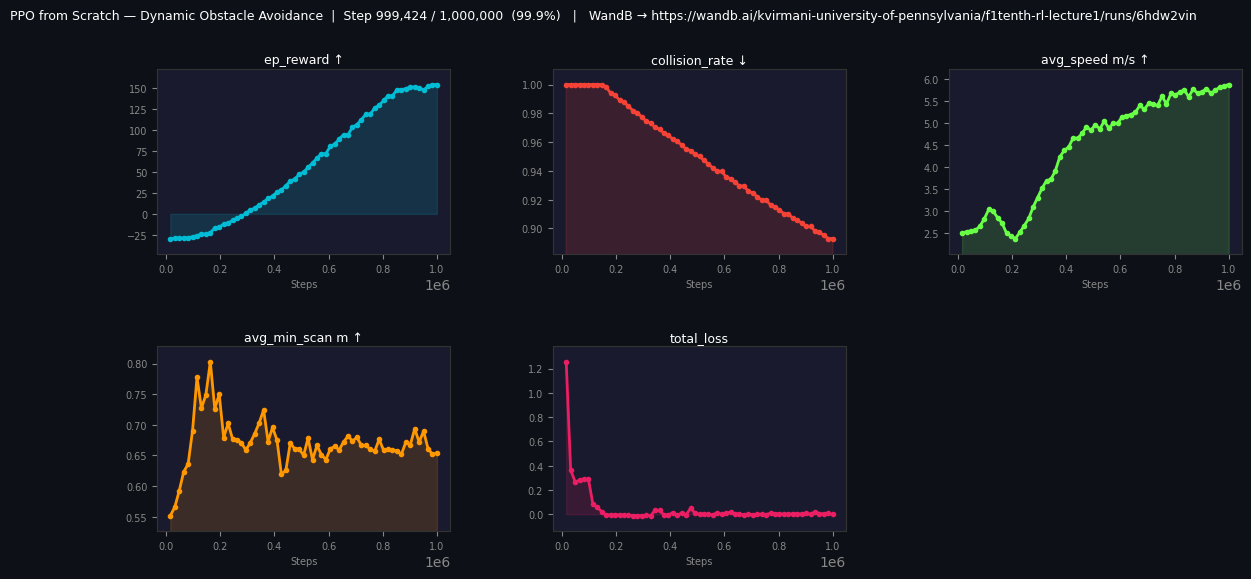

Update 61/61 | step 999,424 | episodes=776 | ep_rew_mean=154.7 | collision_rate=0.89 | loss=-0.0026

Saved → models_dynamic/ppo_scratch_dynamic.pt
Saved → models_dynamic/vecnormalize.pkl


eval/mean_ep_length,▁▅▇▇▄▅▇▄▇▅▇▅█▄▂
eval/mean_reward,▁▂▃▃▂▄▅▃▅▅▆▅█▃▂
global_step,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▃▄▅▅▆█
racing/avg_min_scan,▅▁▄█▄▄▁▂▄▄▁▄▃▁▄▇▅▄▃▂▄▃█▄▄▇▃▄▃▃▆▃▁▅▂▅▅▅▅▅
racing/avg_speed,▂▁▂▃▁▂▃▃▃▃▃▁▁▃▁▂▂▂▂▃▂▂▂▂▂▂▂▃▂▂▃▂▃▁▂▆▃▇██
racing/collision_rate,████████████████████████████████████▆▄▁▁
racing/episode_count,▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▇▇███
rollout/ep_len_mean,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▃▄▅▅▆▇██
rollout/ep_len_std,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▆████
rollout/ep_rew_mean,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▃▃▅▅█
+10,...


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
#  PPO from Scratch — Dynamic Obstacle Avoidance Training (Run This Single Cell)
# ══════════════════════════════════════════════════════════════════════════════
# Identical PPO algorithm to every other notebook in this series. Only the
# environment (a real second agent, randomized every episode) differs.
# ──────────────────────────────────────────────────────────────────────────────

from collections import deque

N_STEPS       = 4096
N_EPOCHS      = 10
MINIBATCH     = 256
GAMMA         = 0.99
GAE_LAMBDA    = 0.95
CLIP_EPS      = 0.2
ENT_COEF      = 0.001
VF_COEF       = 0.5
LR            = 3e-4
MAX_GRAD      = 0.5
EVAL_FREQ     = 50_000
EVAL_EPISODES = 5

torch.manual_seed(42)
np.random.seed(42)

run = wandb.init(
    reinit  = True,
    project = 'f1tenth-rl-lecture1',
    name    = f'ppo_scratch_dynamic_{MAP_NAME}_{TOTAL_STEPS//1000}k',
    config  = dict(n_steps=N_STEPS, n_epochs=N_EPOCHS, gamma=GAMMA,
                   gae_lambda=GAE_LAMBDA, clip_eps=CLIP_EPS, ent_coef=ENT_COEF,
                   lr=LR, map=MAP_NAME, num_envs=NUM_ENVS,
                   opponent_speed_range=OPPONENT_SPEED_RANGE,
                   opponent_spawn_gap_range=OPPONENT_SPAWN_GAP_RANGE,
                   opponent_lookahead_range=OPPONENT_LOOKAHEAD_RANGE),
)
wandb.define_metric('global_step')
wandb.define_metric('*', step_metric='global_step')
print(f'🔗 WandB → {run.url}\n')

train_env = make_training_env(MAP_NAME, NUM_ENVS)
eval_env  = make_eval_env(MAP_NAME)
obs_dim   = train_env.observation_space.shape[0]
act_dim   = train_env.action_space.shape[0]

device = torch.device(DEVICE if torch.cuda.is_available() else 'cpu')
net    = ActorCritic(obs_dim, act_dim).to(device)
opt    = optim.Adam(net.parameters(), lr=LR, eps=1e-5)
print(net)
print(f'Parameters: {sum(p.numel() for p in net.parameters()):,}\n')

episode_count    = 0
total_collisions = 0

cur_rew  = np.zeros(NUM_ENVS)
cur_spd  = [[] for _ in range(NUM_ENVS)]
cur_scan = [[] for _ in range(NUM_ENVS)]
cur_col  = np.zeros(NUM_ENVS, dtype=bool)
cur_len  = np.zeros(NUM_ENVS, dtype=int)

ep_rew_window = deque(maxlen=100)
ep_len_window = deque(maxlen=100)

_live.update({k: [] for k in _live})
update_speeds = []

obs = train_env.reset()
obs = torch.tensor(obs, dtype=torch.float32, device=device)
global_step    = 0
last_eval_step = 0
n_updates      = TOTAL_STEPS // (N_STEPS * NUM_ENVS)

print(f'Training {TOTAL_STEPS:,} steps = {n_updates} updates — plots update below\n')

for update in range(n_updates):
    mb_obs, mb_act, mb_logp, mb_val, mb_rew, mb_done = [], [], [], [], [], []
    update_speeds = []
    update_scans  = []

    for _ in range(N_STEPS):
        action, logp, value = net.act(obs)
        act_np = action.cpu().numpy()
        clipped_np = np.clip(act_np, -1.0, 1.0)
        next_obs, reward, dones, infos = train_env.step(clipped_np)
        raw_reward = train_env.get_original_reward()

        mb_obs.append(obs); mb_act.append(action); mb_logp.append(logp)
        mb_val.append(value)
        mb_rew.append(torch.tensor(reward, dtype=torch.float32, device=device))
        mb_done.append(torch.tensor(dones, dtype=torch.float32, device=device))

        cur_rew += raw_reward
        cur_len += 1
        for i, inf in enumerate(infos):
            spd = inf.get('speed', 0.0)
            cur_spd[i].append(spd)
            cur_scan[i].append(inf.get('min_scan', 0.0))
            update_speeds.append(spd)
            update_scans.append(inf.get('min_scan', 0.0))
            if inf.get('collision', False): cur_col[i] = True

        for i, d in enumerate(dones):
            if d and infos[i].get('TimeLimit.truncated', False):
                term_obs = torch.tensor(
                    infos[i]['terminal_observation'], dtype=torch.float32, device=device
                ).unsqueeze(0)
                with torch.no_grad():
                    _, term_value = net(term_obs)
                mb_rew[-1][i] += GAMMA * term_value.item()

        for i, d in enumerate(dones):
            if d:
                episode_count    += 1
                total_collisions += int(cur_col[i])
                ep_rew_window.append(cur_rew[i])
                ep_len_window.append(cur_len[i])

                wandb.log({
                    'racing/avg_speed':       float(np.mean(cur_spd[i]))  if cur_spd[i]  else 0.0,
                    'racing/avg_min_scan':    float(np.mean(cur_scan[i])) if cur_scan[i] else 0.0,
                    'racing/collision_rate':  total_collisions / episode_count,
                    'racing/episode_count':   episode_count,
                    'rollout/ep_rew_mean':    float(np.mean(ep_rew_window)),
                    'rollout/ep_len_mean':    float(np.mean(ep_len_window)),
                    'rollout/ep_len_std':     float(np.std(ep_len_window)) if len(ep_len_window) > 1 else 0.0,
                    'global_step':            global_step,
                })

                cur_rew[i] = 0.0; cur_spd[i] = []; cur_scan[i] = []
                cur_col[i] = False; cur_len[i] = 0

        obs = torch.tensor(next_obs, dtype=torch.float32, device=device)
        global_step += NUM_ENVS

    with torch.no_grad():
        _, last_value = net(obs)
    rewards = torch.stack(mb_rew)
    values  = torch.stack(mb_val)
    dones_t = torch.stack(mb_done)
    advantages, returns = compute_gae(rewards, values, dones_t, last_value,
                                      gamma=GAMMA, lam=GAE_LAMBDA)

    b_obs     = torch.stack(mb_obs).reshape(-1, obs_dim)
    b_act     = torch.stack(mb_act).reshape(-1, act_dim)
    b_logp    = torch.stack(mb_logp).reshape(-1)
    b_adv     = advantages.reshape(-1)
    b_ret     = returns.reshape(-1)
    b_val_old = values.reshape(-1)

    batch_size = b_obs.shape[0]
    idxs = np.arange(batch_size)
    epoch_losses, epoch_pg, epoch_vf, epoch_ent, epoch_clipfrac, epoch_kl = [], [], [], [], [], []
    for epoch in range(N_EPOCHS):
        np.random.shuffle(idxs)
        for start in range(0, batch_size, MINIBATCH):
            mb = idxs[start:start + MINIBATCH]
            dist, value = net(b_obs[mb])
            new_logp = dist.log_prob(b_act[mb]).sum(-1)
            entropy  = dist.entropy().sum(-1).mean()

            mb_adv = b_adv[mb]
            mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)

            ratio       = torch.exp(new_logp - b_logp[mb])
            surr1       = ratio * mb_adv
            surr2       = torch.clamp(ratio, 1-CLIP_EPS, 1+CLIP_EPS) * mb_adv
            policy_loss = -torch.min(surr1, surr2).mean()
            value_loss  = ((value - b_ret[mb]) ** 2).mean()
            loss        = policy_loss + VF_COEF * value_loss - ENT_COEF * entropy

            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), MAX_GRAD)
            opt.step()

            epoch_losses.append(loss.item())
            epoch_pg.append(policy_loss.item())
            epoch_vf.append(value_loss.item())

            epoch_ent.append(entropy.item())
            with torch.no_grad():
                clip_frac = (torch.abs(ratio - 1.0) > CLIP_EPS).float().mean().item()
            epoch_clipfrac.append(clip_frac)
            with torch.no_grad():
                log_ratio = new_logp - b_logp[mb]
                approx_kl = torch.mean((torch.exp(log_ratio) - 1) - log_ratio).item()
            epoch_kl.append(approx_kl)

    y_true = b_ret.cpu().numpy()
    y_pred = b_val_old.cpu().numpy()
    var_y  = np.var(y_true)
    explained_var = float('nan') if var_y == 0 else 1.0 - np.var(y_true - y_pred) / var_y
    current_std   = net.log_std.exp().mean().item()

    wandb.log({
        'train/loss':                 float(np.mean(epoch_losses)),
        'train/policy_gradient_loss': float(np.mean(epoch_pg)),
        'train/value_loss':           float(np.mean(epoch_vf)),
        'train/std':                  current_std,
        'train/explained_variance':   explained_var,
        'train/learning_rate':        LR,
        'train/entropy_loss':         -float(np.mean(epoch_ent)),
        'train/clip_range':           CLIP_EPS,
        'train/clip_fraction':        float(np.mean(epoch_clipfrac)),
        'train/approx_kl':            float(np.mean(epoch_kl)),
        'global_step':                global_step,
    })

    if global_step - last_eval_step >= EVAL_FREQ:
        last_eval_step = global_step
        eval_env.ret_rms = copy.deepcopy(train_env.ret_rms)

        eval_rewards, eval_lens = [], []
        for _ in range(EVAL_EPISODES):
            eobs = eval_env.reset()
            edone, erew, elen = False, 0.0, 0
            while not edone:
                eobs_t = torch.tensor(eobs, dtype=torch.float32, device=device)
                with torch.no_grad():
                    eaction, _, _ = net.act(eobs_t, deterministic=True)
                eobs, ereward, edones, _ = eval_env.step(eaction.cpu().numpy())
                erew += float(ereward[0]); elen += 1; edone = bool(edones[0])
            eval_rewards.append(erew); eval_lens.append(elen)
        wandb.log({
            'eval/mean_reward':    float(np.mean(eval_rewards)),
            'eval/mean_ep_length': float(np.mean(eval_lens)),
            'global_step':         global_step,
        })
        print(f'  [eval @ {global_step:,}] reward={np.mean(eval_rewards):.1f} '
              f'ep_len={np.mean(eval_lens):.0f}')

    if episode_count > 0:
        _live['steps'].append(global_step)
        _live['rew'].append(float(np.mean(ep_rew_window)))
        _live['collision'].append(total_collisions / episode_count)
        _live['speed'].append(float(np.mean(update_speeds)) if update_speeds else 0.0)
        _live['scan'].append(float(np.mean(update_scans)) if update_scans else 0.0)
        _live['loss'].append(float(np.mean(epoch_losses)))
        draw_live_plots(TOTAL_STEPS)
        print(f'Update {update+1}/{n_updates} | step {global_step:,} | episodes={episode_count} | '
              f'ep_rew_mean={np.mean(ep_rew_window):.1f} | collision_rate={total_collisions/episode_count:.2f} | '
              f'loss={np.mean(epoch_losses):.4f}')

os.makedirs('models_dynamic', exist_ok=True)
torch.save(net.state_dict(), 'models_dynamic/ppo_scratch_dynamic.pt')
train_env.save('models_dynamic/vecnormalize.pkl')
print('\nSaved → models_dynamic/ppo_scratch_dynamic.pt')
print('Saved → models_dynamic/vecnormalize.pkl')
wandb.finish()
train_env.close()
eval_env.close()


---

# **Section 7 — Save Your Trained Model** 💾

In [ ]:
!zip -r models_dynamic_archive.zip /content/models_dynamic

  adding: content/models_dynamic/ (stored 0%)
  adding: content/models_dynamic/vecnormalize.pkl (deflated 52%)
  adding: content/models_dynamic/ppo_scratch_dynamic.pt (deflated 10%)


In [ ]:
from google.colab import files
files.download('models_dynamic_archive.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

# **Section 8 — Evaluation** 🎬

## 8.1 Evaluate Across Random Opponent Scenarios 🧪

Since the wrapper randomizes opponent speed/spawn/lookahead on every
`reset()` automatically, a normal evaluation loop already tests genuinely
different scenarios each episode — no separate held-out pool needed here,
unlike static obstacle avoidance's map variants.

In [ ]:
# ── Evaluate across random opponent scenarios ──────────────────────────────────
eval_env_raw = F1TenthDynamicObstacleWrapper(map_name=MAP_NAME)
eval_net = ActorCritic(eval_env_raw.observation_space.shape[0],
                       eval_env_raw.action_space.shape[0]).to('cpu')
eval_net.load_state_dict(torch.load('models_dynamic/ppo_scratch_dynamic.pt', map_location='cpu'))
eval_net.eval()
print('Loaded models_dynamic/ppo_scratch_dynamic.pt')

NUM_EVAL_EPISODES = 10
all_rewards, all_speeds, all_progress, all_scans = [], [], [], []
print(f'\nRunning {NUM_EVAL_EPISODES} episodes, each with a freshly randomized opponent...')
print('─' * 75)

for ep in range(NUM_EVAL_EPISODES):
    obs, _ = eval_env_raw.reset()
    opp_speed = eval_env_raw.opponent_controller.cruise_speed
    total_reward, done, steps = 0.0, False, 0
    speeds, scans = [], []

    while not done:
        obs_t = torch.tensor(obs, dtype=torch.float32)
        with torch.no_grad():
            action, _, _ = eval_net.act(obs_t, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env_raw.step(action.numpy())
        total_reward += reward; done = terminated or truncated; steps += 1
        speeds.append(info.get('speed', 0.0))
        scans.append(info.get('min_scan', 0.0))

    avg_spd  = np.mean(speeds)
    avg_scan = np.mean(scans)
    progress = info.get('progress', 0)
    crashed  = info.get('collision', False)
    all_rewards.append(total_reward); all_speeds.append(avg_spd)
    all_progress.append(progress); all_scans.append(avg_scan)

    status = 'CRASH' if crashed else ('TIMEOUT' if steps >= 10000 else 'DONE')
    print(f'  Ep {ep+1}: {status} | reward={total_reward:7.1f} | opponent={opp_speed:.2f} m/s | '
          f'speed={avg_spd:.2f} m/s | progress={progress:.3f} | min_scan={avg_scan:.3f}m')

print('─' * 75)
print(f'  Average reward:      {np.mean(all_rewards):.1f} ± {np.std(all_rewards):.1f}')
print(f'  Average speed:       {np.mean(all_speeds):.2f} m/s')
print(f'  Average progress:    {np.mean(all_progress):.3f}')
print(f'  Average min scan:    {np.mean(all_scans):.3f} m')
print(f'  Collision-free eps:  {sum(1 for r in all_rewards if r > -25)}/{NUM_EVAL_EPISODES}')
eval_env_raw.close()


Loaded models_dynamic/ppo_scratch_dynamic.pt

Running 10 episodes, each with a freshly randomized opponent...
───────────────────────────────────────────────────────────────────────────
[WARNING] Could not reposition the opponent — last error: 'F110Simulator' object has no attribute 'agents'
DIAGNOSTIC — sim attributes: ['agent_scans', 'agent_vertices', 'collision_check_mode', 'collisions', 'config', 'control_dim', 'dynamics_fn', 'ego_idx', 'integrator_dt', 'integrator_fn', 'longitudinal_fn', 'longitudinal_type', 'model', 'num_agents', 'params_array', 'reset', 'scan_cache', 'scan_enabled', 'scan_max_range', 'scan_num_beams', 'scan_rngs', 'scan_sims', 'seed', 'set_map', 'standard_state_fn', 'state', 'state_dim', 'steering_fn', 'steering_type', 'step', 'substeps', 'time_step', 'track', 'ttc_threshold', 'update_params', 'vehicle_params']
Opponent will stay wherever the reset strategy placed it until this
is fixed — spawn-offset randomization won't take effect yet.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  Ep 1: CRASH | reward=    0.5 | opponent=2.18 m/s | speed=7.52 m/s | progress=0.072 | min_scan=0.619m
  Ep 2: CRASH | reward=  -16.0 | opponent=2.47 m/s | speed=6.01 m/s | progress=0.052 | min_scan=0.616m
  Ep 3: CRASH | reward=   87.5 | opponent=3.54 m/s | speed=7.79 m/s | progress=0.310 | min_scan=0.659m
  Ep 4: CRASH | reward=   20.1 | opponent=3.54 m/s | speed=7.64 m/s | progress=0.148 | min_scan=0.647m
  Ep 5: CRASH | reward=   40.7 | opponent=3.93 m/s | speed=7.60 m/s | progress=0.222 | min_scan=0.642m
  Ep 6: CRASH | reward=   60.6 | opponent=3.89 m/s | speed=7.75 m/s | progress=0.247 | min_scan=0.651m
  Ep 7: CRASH | reward=   44.8 | opponent=3.14 m/s | speed=7.41 m/s | progress=0.173 | min_scan=0.640m
  Ep 8: CRASH | reward=  -29.7 | opponent=2.12 m/s | speed=3.27 m/s | progress=0.008 | min_scan=0.372m
  Ep 9: CRASH | reward=  117.1 | opponent=2.45 m/s | speed=7.83 m/s | progress=0.259 | min_scan=0.662m
  Ep 10: CRASH | reward=  -29.6 | opponent=2.02 m/s | speed=2.92 m/s | pr

## 8.2 Record Eval Video 🎥

In [ ]:
# ── Record eval video ──────────────────────────────────────────────────────────
!pip install -q imageio imageio-ffmpeg
import imageio

_probe_env = F1TenthDynamicObstacleWrapper(map_name=MAP_NAME)
vid_net = ActorCritic(_probe_env.observation_space.shape[0],
                      _probe_env.action_space.shape[0]).to('cpu')
_probe_env.close()
vid_net.load_state_dict(torch.load('models_dynamic/ppo_scratch_dynamic.pt', map_location='cpu'))
vid_net.eval()

venv = DummyVecEnv([lambda: F1TenthDynamicObstacleWrapper(map_name=MAP_NAME, render_mode='rgb_array')])
venv = VecMonitor(venv)
venv = VecNormalize.load('models_dynamic/vecnormalize.pkl', venv)
venv.training = False; venv.norm_reward = False

frames = []
obs = venv.reset(); done = False; step = 0
while not done and step < 5000:
    obs_t = torch.tensor(obs, dtype=torch.float32)
    with torch.no_grad():
        action, _, _ = vid_net.act(obs_t, deterministic=True)
    obs, _, dones, _ = venv.step(action.numpy())
    done = dones[0]; step += 1
    if step % 5 == 0:
        frame = venv.envs[0].render()
        if frame is not None: frames.append(frame)
venv.close()

if frames:
    print(f'✅ Captured {len(frames)} frames')
    imageio.mimsave('eval_render_dynamic.mp4', frames, fps=20)
    from google.colab import files
    files.download('eval_render_dynamic.mp4')
else:
    print('❌ No frames captured')


/usr/local/lib/python3.13/dist-packages/pyqtgraph/parametertree/Parameter.py:140: DeprecationWarning: Parameter has no default value. Pass a default, or use setDefault(). This will no longer set an implicit default after January 2025.
  return cls(**opts)


[WARNING] Could not reposition the opponent — last error: 'F110Simulator' object has no attribute 'agents'
DIAGNOSTIC — sim attributes: ['agent_scans', 'agent_vertices', 'collision_check_mode', 'collisions', 'config', 'control_dim', 'dynamics_fn', 'ego_idx', 'integrator_dt', 'integrator_fn', 'longitudinal_fn', 'longitudinal_type', 'model', 'num_agents', 'params_array', 'reset', 'scan_cache', 'scan_enabled', 'scan_max_range', 'scan_num_beams', 'scan_rngs', 'scan_sims', 'seed', 'set_map', 'standard_state_fn', 'state', 'state_dim', 'steering_fn', 'steering_type', 'step', 'substeps', 'time_step', 'track', 'ttc_threshold', 'update_params', 'vehicle_params']
Opponent will stay wherever the reset strategy placed it until this
is fixed — spawn-offset randomization won't take effect yet.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


✅ Captured 17 frames


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

# **Section 9 — Summary** 📝

## What We Built

A policy that reacts to a genuinely moving obstacle, not a memorized
choreography:

1. **Real multi-agent support** — a second car (`num_agents=2`), controlled
   by pure pursuit, sharing the track with the ego. No fragile file-based
   workarounds needed, unlike static obstacle avoidance.
2. **Randomized every episode** — the opponent's speed, spawn offset, and
   lookahead distance all vary, so the ego can't solve this by memorizing one
   fixed scenario.
3. **The actuator fix from Learn to Race carried forward** — `STEERING_SPEED`
   control mode applies to both agents, so neither the ego nor the opponent
   wobbles from the bang-bang `STEERING_ANGLE` actuator bug.
4. **The same reward philosophy as static obstacle avoidance** — no
   centerline-tracking penalty, since the exact behavior we want (deviating
   to avoid something in the way) is what that penalty would fight.

The PPO algorithm — network, GAE, clipped loss — never changed across any
notebook in this entire series. Every meaningful capability, from driving to
racing to avoiding a static obstacle to avoiding a moving one, came from the
environment and the reward. We now have a policy ready to do head-to-head racing with!

---

# **Coming Up Next** 🔜

This notebook trains and evaluates entirely in simulation. Getting this onto
the **physical car** is the natural next step, and a short summary of what
that involves:

- **Sim-to-real gap** — the real car's lidar is noisier and the dynamics
  (tire grip, motor response, latency) won't match the simulator exactly, so
  expect the policy to need some fine-tuning or domain-randomization-in-sim
  before it transfers cleanly.
- **Wrap the policy as a ROS 2 node** — load the trained weights, subscribe to
  the real `/scan` topic, run the same `_process_obs` normalization used here,
  and publish an `AckermannDriveStamped` command instead of stepping a gym env.
- **Control-loop timing** — the real car needs the policy to run at a
  consistent rate (e.g. ~40-100 Hz); profile inference time on the onboard
  compute (e.g. Jetson) and downsample lidar beams if needed to hit it.
- **Safety first** — start with a speed cap well below `max_speed`, test on an
  empty track before adding a real second car, and keep a manual override /
  e-stop active the whole time.
- **Real opponents, not pure pursuit** — on the physical track, "dynamic
  obstacle" means an actual second car (autonomous or human-driven), so the
  policy's generalization — not the opponent's exact controller — is what
  gets tested.
